In [ ]:
#FASE USA – Código base de Yahtzee
import random
from collections import Counter, defaultdict
from dataclasses import dataclass, field
from typing import List, Dict, Optional, Tuple

# ===============================
# Parámetros Montecarlo
# ===============================
SIMS_PER_MASK = 300  # nº de simulaciones por máscara de bloqueo (32 máx). Ajusta si quieres más/menos precisión.
SEED = 42            # fija semilla para reproducibilidad; pon None para aleatorio

if SEED is not None:
    random.seed(SEED)

# ===============================
# Utilidades de dados
# ===============================
def roll_single_die() -> int:
    """Devuelve un entero uniforme en [1,6]."""
    return random.randint(1, 6)

def roll_dice(values: List[int], locked: List[bool]) -> None:
    """Lanza dados no bloqueados, actualizando 'values' in place."""
    for i, is_locked in enumerate(locked):
        if not is_locked:
            values[i] = roll_single_die()

def has_sequence(values: List[int], needed_len: int) -> bool:
    """¿Existe una secuencia consecutiva de longitud 'needed_len'? (ignora duplicados)."""
    uniq = sorted(set(values))
    if not uniq:
        return False
    longest = curr = 1
    for i in range(1, len(uniq)):
        if uniq[i] == uniq[i-1] + 1:
            curr += 1
            longest = max(longest, curr)
        else:
            curr = 1
    return longest >= needed_len

# ===============================
# Puntuación
# ===============================
CATEGORIES_ORDER = [
    "ones","twos","threes","fours","fives","sixes",
    "threeOfKind","fourOfKind","fullHouse","smallStraight",
    "largeStraight","yahtzee","chance"
]

def score_hand(category: str, dice: List[int]) -> int:
    counts = Counter(dice)
    freqs = list(counts.values())
    total = sum(dice)
    if category in ["ones","twos","threes","fours","fives","sixes"]:
        num = {"ones":1, "twos":2, "threes":3, "fours":4, "fives":5, "sixes":6}[category]
        return counts.get(num, 0) * num
    if category == "threeOfKind":
        return total if any(f >= 3 for f in freqs) else 0
    if category == "fourOfKind":
        return total if any(f >= 4 for f in freqs) else 0
    if category == "fullHouse":
        return 25 if (2 in freqs and 3 in freqs) else 0
    if category == "smallStraight":
        return 30 if has_sequence(dice, 4) else 0
    if category == "largeStraight":
        return 40 if has_sequence(dice, 5) else 0
    if category == "yahtzee":
        return 50 if 5 in freqs else 0
    if category == "chance":
        return total
    return 0

def best_category_score(dice: List[int], available: List[str]) -> Tuple[str, int]:
    """Devuelve (mejor_categoria, puntuación) para los dados dados."""
    best_cat, best = None, -1
    for cat in available:
        sc = score_hand(cat, dice)
        if sc > best:
            best = sc
            best_cat = cat
    return best_cat, best

# ===============================
# Estructuras de juego
# ===============================
@dataclass
class PlayerState:
    name: str
    scores: Dict[str, Optional[int]] = field(default_factory=lambda: {c: None for c in CATEGORIES_ORDER})
    total: int = 0

    def available_categories(self) -> List[str]:
        return [c for c,v in self.scores.items() if v is None]

    def set_score(self, category: str, points: int) -> None:
        self.scores[category] = points
        self.total = sum(v for v in self.scores.values() if v is not None)

@dataclass
class GameStats:
    total_rolls: int = 0
    face_hist: Counter = field(default_factory=Counter)

    def update_from_roll(self, values: List[int]) -> None:
        # 'values' contiene únicamente los dados que se lanzaron en esta tirada.
        self.total_rolls += len(values)
        self.face_hist.update(values)

@dataclass
class GameState:
    players: List[PlayerState]
    current_player_idx: int = 0
    turn_in_round: int = 0  # 0..12 (13 turnos)
    dice_values: List[int] = field(default_factory=lambda: [0]*5)
    locked: List[bool] = field(default_factory=lambda: [False]*5)
    rolls_left: int = 3
    stats: GameStats = field(default_factory=GameStats)

    def reset_turn(self):
        self.dice_values = [0]*5
        self.locked = [False]*5
        self.rolls_left = 3

    @property
    def current_player(self) -> PlayerState:
        return self.players[self.current_player_idx]

    def advance_player(self):
        self.current_player_idx = (self.current_player_idx + 1) % len(self.players)
        if self.current_player_idx == 0:
            self.turn_in_round += 1

# ===============================
# Montecarlo para decidir bloqueos
# ===============================
def all_keep_masks() -> List[List[bool]]:
    """Genera las 32 máscaras posibles de bloqueo para 5 dados."""
    masks = []
    for m in range(32):  # 0..31
        mask = [(m >> i) & 1 == 1 for i in range(5)]
        masks.append(mask)
    return masks

def simulate_expected_value_after_keeps(
    current_values: List[int],
    keep_mask: List[bool],
    rolls_remaining: int,
    available_categories: List[str],
    sims: int
) -> float:
    """
    Estima el valor esperado de la mejor categoría si:
    - conservas (keep_mask) algunos dados ahora,
    - y después solo rerolléas los no conservados el número de veces restante,
    - sin volver a cambiar la máscara (aprox. Montecarlo de 1 paso).
    """
    if rolls_remaining <= 0:
        # Sin tiradas: solo puntuar ahora
        _, sc = best_category_score(current_values, available_categories)
        return float(sc)

    kept = [v if keep_mask[i] else None for i, v in enumerate(current_values)]
    unlocked_idx = [i for i,b in enumerate(keep_mask) if not b]

    total_score = 0.0
    for _ in range(sims):
        # Copia de valores
        vals = kept[:]
        # Rerolls: tirar los no conservados 'rolls_remaining' veces, quedándose con la última
        temp = current_values[:]  # por si keep None
        for _r in range(rolls_remaining):
            for i in unlocked_idx:
                temp[i] = roll_single_die()
        # Construir resultado final
        for i in range(5):
            vals[i] = vals[i] if vals[i] is not None else temp[i]

        # Mejor categoría al final
        _, sc = best_category_score(vals, available_categories)
        total_score += sc

    return total_score / sims if sims > 0 else 0.0

def choose_keep_mask_montecarlo(
    current_values: List[int],
    rolls_remaining: int,
    available_categories: List[str],
    sims_per_mask: Optional[int] = None
) -> List[bool]:
    """
    Elige la máscara de bloqueo que maximiza el valor esperado estimado al final del turno.
    Nota: aproximación de 1 paso (no recalcula bloqueos tras la siguiente tirada durante la simulación).
    """
    if sims_per_mask is None:
        sims_per_mask = SIMS_PER_MASK
    best_mask = None
    best_ev = -1.0
    for mask in all_keep_masks():
        # Si el jugador decide "plantarse" ahora, la máscara sería keep todo (no cambia nada).
        ev = simulate_expected_value_after_keeps(
            current_values, mask, rolls_remaining, available_categories, sims_per_mask
        )
        if ev > best_ev:
            best_ev = ev
            best_mask = mask
    return best_mask

# ===============================
# Flujo del juego
# ===============================
def play_one_turn(state: GameState, verbose: bool = True):
    """Un turno completo para el jugador actual: hasta 3 tiradas + elección de categoría."""
    player = state.current_player
    state.reset_turn()

    # Tirada inicial
    roll_dice(state.dice_values, state.locked)
    state.stats.update_from_roll(state.dice_values)
    state.rolls_left -= 1
    if verbose:
        print(f"\n{player.name} — Tirada 1:", state.dice_values)

    # Hasta 2 rerolls con estrategia MC
    while state.rolls_left > 0:
        keep_mask = choose_keep_mask_montecarlo(
            state.dice_values, state.rolls_left, player.available_categories()
        )

        # Si la máscara "keep_mask" implica mantener todo tal cual (keep 5), podemos decidir plantarnos:
        if all(keep_mask):
            if verbose:
                print(f"{player.name} decide plantarse con:", state.dice_values)
            break

        # Bloquear según la máscara y registrar cuáles dados se volverán a lanzar
        state.locked = keep_mask[:]
        rolled_indices = [i for i, is_locked in enumerate(state.locked) if not is_locked]

        # Reroll: actualizar estadísticas solo con los dados que realmente se lanzaron
        roll_dice(state.dice_values, state.locked)
        rolled_values = [state.dice_values[i] for i in rolled_indices]
        state.stats.update_from_roll(rolled_values)
        state.rolls_left -= 1
        if verbose:
            tirada_num = 3 - state.rolls_left
            print(f"{player.name} — Tirada {tirada_num}:", state.dice_values, "| keep:", keep_mask)

    # Elegir mejor categoría disponible para la mano final
    cat, sc = best_category_score(state.dice_values, player.available_categories())
    player.set_score(cat, sc)
    if verbose:
        print(f"→ {player.name} elige categoría '{cat}' y anota {sc} puntos. Total = {player.total}")

def play_game(verbose_each_turn: bool = False) -> GameState:
    players = [PlayerState("Jugador 1"), PlayerState("Jugador 2")]
    state = GameState(players=players)
    total_rounds = 13

    print("🎲 Iniciando simulación de Montecarlo (Motor de IA tomando decisiones)...")
    for r in range(total_rounds):
        for _p in range(len(players)):
            play_one_turn(state, verbose=verbose_each_turn)
            state.advance_player()  # <--- ¡Esta es la línea que faltaba!
    print("✅ Simulación completada.\n")
    return state

# ===============================
# Ejecutar simulación completa
# ===============================
state = play_game(verbose_each_turn=True)

# ===============================
# Mostrar resultados
# ===============================
def print_scoreboard(state: GameState):
    print("\n\n===== MARCADOR FINAL =====")
    for p in state.players:
        print(f"\n{p.name}: {p.total} puntos")
        for cat in CATEGORIES_ORDER:
            v = p.scores[cat]
            print(f"  - {cat:13s}: {v if v is not None else 0}")
    # Ganador
    if state.players[0].total > state.players[1].total:
        winner = state.players[0].name
    elif state.players[1].total > state.players[0].total:
        winner = state.players[1].name
    else:
        winner = "Empate"
    print(f"\n🏆 Ganador: {winner}")

def print_stats(state: GameState):
    print("\n===== ESTADÍSTICAS =====")
    print(f"Total de lanzamientos (dados individuales): {state.stats.total_rolls}")
    total_faces = sum(state.stats.face_hist.values())
    for face in range(1,7):
        c = state.stats.face_hist.get(face, 0)
        p = (c/total_faces)*100 if total_faces else 0.0
        print(f" Cara {face}: {c} veces ({p:.2f}%)")

print_scoreboard(state)
print_stats(state)

🎲 Iniciando simulación de Montecarlo (Motor de IA tomando decisiones)...

Jugador 1 — Tirada 1: [6, 1, 1, 6, 3]
Jugador 1 — Tirada 2: [6, 5, 6, 6, 2] | keep: [True, False, False, True, False]
Jugador 1 — Tirada 3: [6, 5, 6, 6, 2] | keep: [True, True, True, True, False]
→ Jugador 1 elige categoría 'threeOfKind' y anota 25 puntos. Total = 25

Jugador 2 — Tirada 1: [1, 3, 5, 2, 6]
Jugador 2 — Tirada 2: [5, 3, 5, 1, 6] | keep: [False, True, True, False, True]
Jugador 2 — Tirada 3: [5, 3, 3, 1, 6] | keep: [True, True, False, False, True]
→ Jugador 2 elige categoría 'chance' y anota 18 puntos. Total = 18

Jugador 1 — Tirada 1: [4, 5, 2, 1, 2]
Jugador 1 — Tirada 2: [4, 5, 2, 2, 2] | keep: [True, True, False, False, True]
Jugador 1 — Tirada 3: [4, 5, 6, 2, 4] | keep: [True, True, False, False, False]
→ Jugador 1 elige categoría 'chance' y anota 21 puntos. Total = 46

Jugador 2 — Tirada 1: [5, 1, 1, 3, 3]
Jugador 2 — Tirada 2: [5, 3, 1, 3, 1] | keep: [True, False, False, True, False]
Jugador 2 

In [ ]:
#FASE MODIFICA: COMPARACIÓN DEL DADO EQUILIBRADO Y CARGADO

import random

# 1. Definir el dado cargado: el seis tiene probabilidad del 30 %
def roll_single_die_cargado():
    return random.choices(
        [1, 2, 3, 4, 5, 6],
        weights=[14, 14, 14, 14, 14, 30],
        k=1
    )[0]


# 2. Guardar la configuración original
_roll_original_modifica = roll_single_die
_sims_original_modifica = SIMS_PER_MASK


# 3. Función para ejecutar una partida con el dado seleccionado
def ejecutar_partida_comparativa(funcion_dado, semilla=2026):
    global roll_single_die, SIMS_PER_MASK

    roll_single_die = funcion_dado
    SIMS_PER_MASK = 100

    random.seed(semilla)

    try:
        resultado = play_game(verbose_each_turn=False)
    finally:
        # Restaurar el dado y las simulaciones originales
        roll_single_die = _roll_original_modifica
        SIMS_PER_MASK = _sims_original_modifica

    return resultado


# 4. Ejecutar partida con dado equilibrado
print("\n===== PARTIDA CON DADO EQUILIBRADO =====")

resultado_normal = ejecutar_partida_comparativa(
    _roll_original_modifica
)


# 5. Ejecutar partida con dado cargado
print("\n===== PARTIDA CON DADO CARGADO =====")

resultado_cargado = ejecutar_partida_comparativa(
    roll_single_die_cargado
)


# 6. Comparar los resultados
print("\n===== COMPARACIÓN FINAL =====")

for nombre, resultado in [
    ("Dado equilibrado", resultado_normal),
    ("Dado cargado", resultado_cargado)
]:

    print(f"\n{nombre}:")

    for jugador in resultado.players:
        print(f"{jugador.name}: {jugador.total} puntos")

    total_caras = sum(resultado.stats.face_hist.values())

    if total_caras > 0:
        seis = resultado.stats.face_hist.get(6, 0)
        porcentaje_seis = seis / total_caras * 100

        print(
            f"Frecuencia observada del seis: "
            f"{porcentaje_seis:.2f}%"
        )

    print(
        f"Total de puntos: "
        f"{sum(p.total for p in resultado.players)}"
    )

print("\n✅ COMPARACIÓN COMPLETADA")
print("La configuración original del dado fue restaurada.")



===== PARTIDA CON DADO EQUILIBRADO =====
🎲 Iniciando simulación de Montecarlo (Motor de IA tomando decisiones)...
✅ Simulación completada.


===== PARTIDA CON DADO CARGADO =====
🎲 Iniciando simulación de Montecarlo (Motor de IA tomando decisiones)...
✅ Simulación completada.


===== COMPARACIÓN FINAL =====

Dado equilibrado:
Jugador 1: 212 puntos
Jugador 2: 211 puntos
Frecuencia observada del seis: 18.52%
Total de puntos: 423

Dado cargado:
Jugador 1: 275 puntos
Jugador 2: 207 puntos
Frecuencia observada del seis: 28.86%
Total de puntos: 482

✅ COMPARACIÓN COMPLETADA
La configuración original del dado fue restaurada.


✅ Diagrama de flujo generado y guardado como 'diagrama_flujo_yahtzee.png'

⏳ Iniciando experimento de convergencia...
   Iteraciones:     10 | EV Estimado: 14.2000 | Tiempo: 0.0011s
   Iteraciones:    100 | EV Estimado: 17.6100 | Tiempo: 0.0024s
   Iteraciones:    500 | EV Estimado: 17.5120 | Tiempo: 0.0117s
   Iteraciones:   1000 | EV Estimado: 17.1070 | Tiempo: 0.0223s
   Iteraciones:   5000 | EV Estimado: 17.2562 | Tiempo: 0.1114s
   Iteraciones:  10000 | EV Estimado: 17.1677 | Tiempo: 0.2284s
   Iteraciones:  50000 | EV Estimado: 17.2210 | Tiempo: 1.1599s
   Iteraciones: 100000 | EV Estimado: 17.2415 | Tiempo: 1.8090s


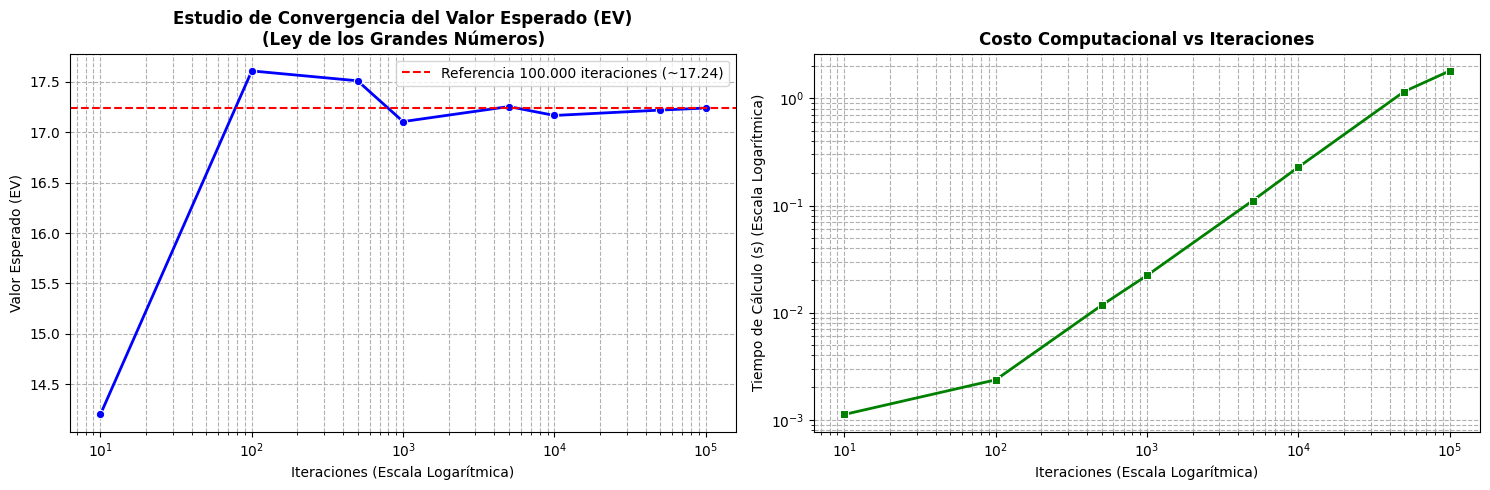

In [ ]:
#USA – Diagrama de flujo y convergencia
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from graphviz import Digraph


# 1. GENERACIÓN DEL DIAGRAMA DE FLUJO (Graphviz)

def generar_diagrama_flujo():
    dot = Digraph(comment='Algoritmo Yahtzee Montecarlo', format='png')
    dot.attr(rankdir='TB', size='8,10', dpi='300')

    # Estilos de nodos
    dot.attr('node', shape='box', style='filled,rounded', color='black', fillcolor='#E3F2FD', fontname='Arial', fontsize='10')

    # Definir nodos
    dot.node('inicio', 'Inicio de Turno\n(Tirada Inicial: 5 Dados)', fillcolor='#C8E6C9', shape='ellipse')
    dot.node('eval_tiros', '¿Quedan tiros disponibles\n(rolls_left > 0)?', shape='diamond', fillcolor='#FFF9C4')
    dot.node('eval_mascaras', 'Evaluar las 32 Máscaras\nPosibles de Bloqueo (Keep Masks)', fillcolor='#E1BEE7')
    dot.node('montecarlo', 'Para cada máscara:\nSimular escenarios futuros (N lanzamientos)\ny calcular Valor Esperado (EV)', fillcolor='#BBDEFB')
    dot.node('mejor_mascara', 'Seleccionar máscara con\nmáximo Valor Esperado (EV)', fillcolor='#BBDEFB')
    dot.node('plantarse', '¿La mejor máscara es\nmantener todos los dados?', shape='diamond', fillcolor='#FFF9C4')
    dot.node('actualizar_dados', 'Lanzar dados no bloqueados\nDisminuir rolls_left', fillcolor='#FFE0B2')
    dot.node('anotar', 'Anotar en la mejor categoría\ndisponible en la hoja', fillcolor='#F8BBD0')
    dot.node('fin', 'Fin del Turno', fillcolor='#FFCDD2', shape='ellipse')

    # Conexiones
    dot.edge('inicio', 'eval_tiros')
    dot.edge('eval_tiros', 'eval_mascaras', label='Sí')
    dot.edge('eval_tiros', 'anotar', label='No')
    dot.edge('eval_mascaras', 'montecarlo')
    dot.edge('montecarlo', 'mejor_mascara')
    dot.edge('mejor_mascara', 'plantarse')
    dot.edge('plantarse', 'anotar', label='Sí')
    dot.edge('plantarse', 'actualizar_dados', label='No')
    dot.edge('actualizar_dados', 'eval_tiros')
    dot.edge('anotar', 'fin')

    return dot

# Guardar y renderizar el diagrama de flujo
dot = generar_diagrama_flujo()
dot.render('diagrama_flujo_yahtzee', cleanup=True)
print("✅ Diagrama de flujo generado y guardado como 'diagrama_flujo_yahtzee.png'")


# 2. ESTUDIO DE CONVERGENCIA (Ley de los Grandes Números)

def reporte_convergencia_lln():
    # Escenario de dados de prueba: Buscamos Full House o Trío con dados iniciales [3, 3, 5, 2, 6]
    dados_iniciales = [3, 3, 3, 2, 6]
    categorias_disponibles = ["threes", "fullHouse", "threeOfKind", "chance"]
    # Queremos evaluar mantener los tres 3s (Máscara: [True, True, True, False, False])
    mascara_keep = [True, True, True, False, False]

    valores_iteraciones = [10, 100, 500, 1000, 5000, 10000, 50000, 100000]
    ev_estimados = []
    tiempos = []

    print("\n⏳ Iniciando experimento de convergencia...")
    for sims in valores_iteraciones:
        t_init = time.time()
        ev = simulate_expected_value_after_keeps(
            current_values=dados_iniciales,
            keep_mask=mascara_keep,
            rolls_remaining=2,
            available_categories=categorias_disponibles,
            sims=sims
        )
        t_elapsed = time.time() - t_init
        ev_estimados.append(ev)
        tiempos.append(t_elapsed)
        print(f"   Iteraciones: {sims:6d} | EV Estimado: {ev:.4f} | Tiempo: {t_elapsed:.4f}s")

    # Crear DataFrame de resultados
    df_conv = pd.DataFrame({
        "Iteraciones": valores_iteraciones,
        "EV Estimado": ev_estimados,
        "Tiempo de Cálculo (s)": tiempos
    })

    # Graficar la Convergencia
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

    # Subplot 1: Convergencia de EV (Ley de los Grandes Números)
    sns.lineplot(x="Iteraciones", y="EV Estimado", data=df_conv, ax=ax1, marker="o", color="b", linewidth=2)
    ax1.set_xscale('log')
    # Referencia empírica: estimación obtenida con el mayor número de iteraciones
    valor_referencia = ev_estimados[-1]
    ax1.axhline(y=valor_referencia, color='r', linestyle='--', label=f'Referencia 100.000 iteraciones (~{valor_referencia:.2f})')
    ax1.set_title("Estudio de Convergencia del Valor Esperado (EV)\n(Ley de los Grandes Números)", fontsize=12, fontweight='bold')
    ax1.set_xlabel("Iteraciones (Escala Logarítmica)")
    ax1.set_ylabel("Valor Esperado (EV)")
    ax1.legend()
    ax1.grid(True, which="both", ls="--")

    # Subplot 2: Costo Computacional (Tiempo vs Iteraciones)
    sns.lineplot(x="Iteraciones", y="Tiempo de Cálculo (s)", data=df_conv, ax=ax2, marker="s", color="g", linewidth=2)
    ax2.set_xscale('log')
    ax2.set_yscale('log')
    ax2.set_title("Costo Computacional vs Iteraciones", fontsize=12, fontweight='bold')
    ax2.set_xlabel("Iteraciones (Escala Logarítmica)")
    ax2.set_ylabel("Tiempo de Cálculo (s) (Escala Logarítmica)")
    ax2.grid(True, which="both", ls="--")

    plt.tight_layout()
    plt.show()

# Ejecutar el análisis
reporte_convergencia_lln()



In [ ]:
# FASE CREA: decisión con tres dados iguales
# Comparación mediante Monte Carlo

dados = [3, 3, 3, 2, 6]
categorias = ["threes", "fullHouse", "threeOfKind", "chance"]

# Opción A: conservar los tres dados iguales y relanzar los otros dos
mascara_tres = [True, True, True, False, False]

# Opción B: conservar los cinco dados y puntuar inmediatamente
mascara_todos = [True, True, True, True, True]

simulaciones = 100000

ev_tres = simulate_expected_value_after_keeps(
    current_values=dados,
    keep_mask=mascara_tres,
    rolls_remaining=2,
    available_categories=categorias,
    sims=simulaciones
)

ev_todos = simulate_expected_value_after_keeps(
    current_values=dados,
    keep_mask=mascara_todos,
    rolls_remaining=2,
    available_categories=categorias,
    sims=simulaciones
)

print("=== FASE CREA: TOMA DE DECISIONES ===")
print("Dados iniciales:", dados)
print("Simulaciones:", simulaciones)
print(f"EV conservando tres dados: {ev_tres:.4f}")
print(f"EV conservando los cinco: {ev_todos:.4f}")

if ev_tres > ev_todos:
    print("DECISIÓN: conservar tres dados y relanzar los otros dos.")
elif ev_todos > ev_tres:
    print("DECISIÓN: conservar los cinco dados y puntuar.")
else:
    print("DECISIÓN: ambas alternativas tienen el mismo valor esperado.")


=== FASE CREA: TOMA DE DECISIONES ===
Dados iniciales: [3, 3, 3, 2, 6]
Simulaciones: 100000
EV conservando tres dados: 17.2402
EV conservando los cinco: 17.0000
DECISIÓN: conservar tres dados y relanzar los otros dos.


### FASE DEBATE: ¿Monte Carlo puede reemplazar el análisis combinatorio?

Monte Carlo no reemplaza completamente el análisis combinatorio; ambos métodos se complementan. El análisis combinatorio permite calcular probabilidades exactas mediante herramientas matemáticas, mientras que Monte Carlo estima resultados mediante experimentos aleatorios repetidos.

En nuestro ejercicio, al aumentar las iteraciones, el valor esperado tiende a estabilizarse, como explica la Ley de los Grandes Números. Sin embargo, Monte Carlo requiere tiempo de procesamiento y presenta variaciones estadísticas.

Por esta razón, considero que Monte Carlo es una herramienta útil para evaluar estrategias y escenarios, pero no sustituye los cálculos exactos cuando estos son posibles.

 📊 ANÁLISIS DE LA PARTIDA Y TOMA DE DECISIONES

🏆 Resultado de la Simulación: ¡El ganador es Jugador 2!

    Categoría  Jugador 1  Jugador 2
         ones          2          3
         twos          4          2
       threes          6          3
        fours          8         12
        fives         15         15
        sixes         18          6
  threeOfKind         25         19
   fourOfKind         25         27
    fullHouse         25         25
smallStraight         30         30
largeStraight         40         40
      yahtzee          0         50
       chance         21         18
------------------------------
PUNTUACIÓN TOTAL | Jugador 1: 219 | Jugador 2: 250


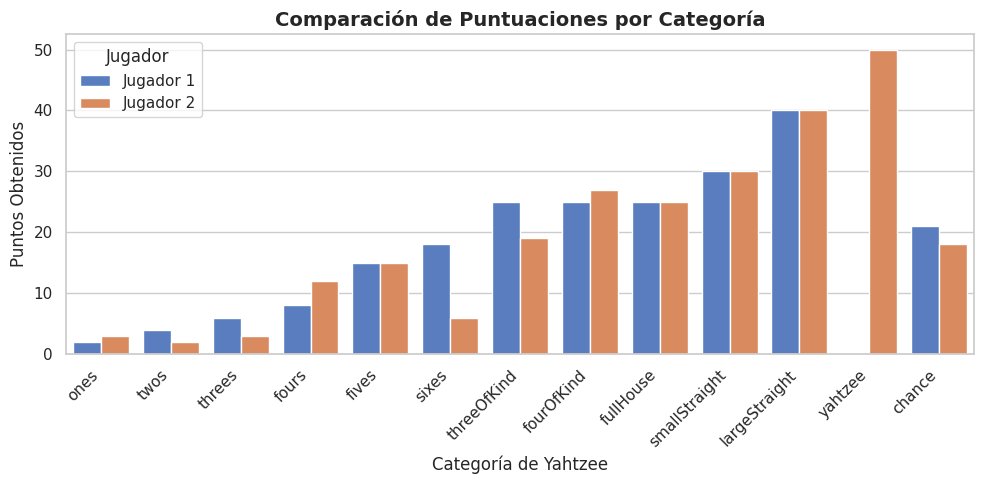


 🎲 ANÁLISIS DEL MOTOR DE DADOS (Validación de Montecarlo)

En una simulación de Montecarlo, es vital comprobar si nuestro generador aleatorio es justo.
Teóricamente, cada cara de un dado perfecto tiene una probabilidad de: 1/6 = 16.67%
Veamos cómo se comportaron nuestros dados tras 260 lanzamientos individuales:

 Cara 1: Salió 43 veces -> 16.54% (Diferencia vs Teoría: 0.13%)
 Cara 2: Salió 32 veces -> 12.31% (Diferencia vs Teoría: 4.36%)
 Cara 3: Salió 45 veces -> 17.31% (Diferencia vs Teoría: 0.64%)
 Cara 4: Salió 43 veces -> 16.54% (Diferencia vs Teoría: 0.13%)
 Cara 5: Salió 43 veces -> 16.54% (Diferencia vs Teoría: 0.13%)
 Cara 6: Salió 54 veces -> 20.77% (Diferencia vs Teoría: 4.10%)


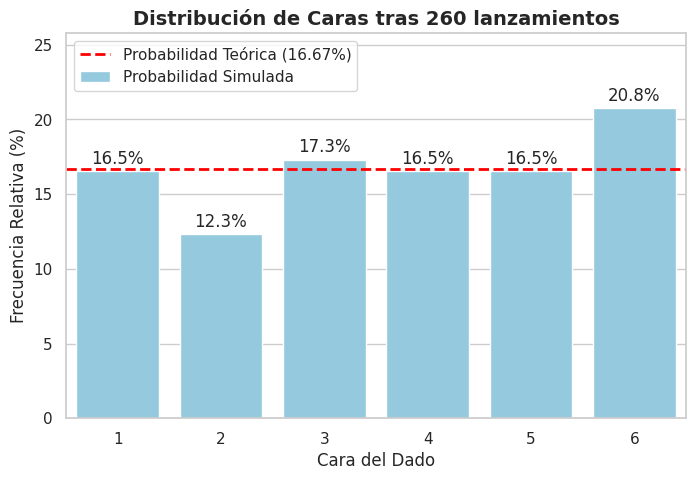


💡 REFLEXIÓN DIDÁCTICA:
Observa el gráfico de distribución. La línea punteada roja representa la probabilidad matemática ideal.
Las barras muestran las frecuencias observadas en esta partida y se comparan con el 16.67% esperado.
Esta muestra es ilustrativa; la convergencia se estudia con el experimento independiente de 10 a 100.000 iteraciones.


In [ ]:
#RESULTADOS Y CONCLUSIONES – Análisis de la partida
# Librerías para análisis y visualización
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# REFACTORIZACIÓN DIDÁCTICA: ANÁLISIS Y VISUALIZACIÓN
# =========================================================
def analisis_didactico_resultados(state: GameState):
    """Presenta los resultados de la simulación de forma visual y pedagógica."""

    # Configuración visual de Seaborn
    sns.set_theme(style="whitegrid")

    # --- 1. RESUMEN DEL PARTIDO (TABLA VISUAL) ---
    print("="*50)
    print(" 📊 ANÁLISIS DE LA PARTIDA Y TOMA DE DECISIONES")
    print("="*50)

    # Determinamos al ganador
    p1, p2 = state.players
    if p1.total > p2.total:
        ganador = p1.name
    elif p2.total > p1.total:
        ganador = p2.name
    else:
        ganador = "Empate"

    print(f"\n🏆 Resultado de la Simulación: ¡El ganador es {ganador}!\n")

    # Construimos un DataFrame de Pandas para que los estudiantes vean una tabla estructurada
    df_scores = pd.DataFrame({
        "Categoría": CATEGORIES_ORDER,
        p1.name: [p1.scores[c] if p1.scores[c] is not None else 0 for c in CATEGORIES_ORDER],
        p2.name: [p2.scores[c] if p2.scores[c] is not None else 0 for c in CATEGORIES_ORDER]
    })

    # Mostramos la tabla formateada
    print(df_scores.to_string(index=False))
    print("-" * 30)
    print(f"PUNTUACIÓN TOTAL | {p1.name}: {p1.total} | {p2.name}: {p2.total}")

    # --- GRÁFICO 1: COMPARACIÓN DE PUNTUACIONES ---
    plt.figure(figsize=(10, 5))
    ax = sns.barplot(x="Categoría", y="Valor", hue="Jugador",
                     data=pd.melt(df_scores, id_vars="Categoría", var_name="Jugador", value_name="Valor"),
                     palette="muted")
    plt.title("Comparación de Puntuaciones por Categoría", fontsize=14, fontweight="bold")
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("Puntos Obtenidos")
    plt.xlabel("Categoría de Yahtzee")
    plt.tight_layout()
    plt.show()

    # --- 2. ANÁLISIS DE PROBABILIDAD Y LA LEY DE LOS GRANDES NÚMEROS ---
    print("\n" + "="*50)
    print(" 🎲 ANÁLISIS DEL MOTOR DE DADOS (Validación de Montecarlo)")
    print("="*50)
    print("\nEn una simulación de Montecarlo, es vital comprobar si nuestro generador aleatorio es justo.")
    print(f"Teóricamente, cada cara de un dado perfecto tiene una probabilidad de: 1/6 = 16.67%")
    print(f"Veamos cómo se comportaron nuestros dados tras {state.stats.total_rolls} lanzamientos individuales:\n")



    total_faces = sum(state.stats.face_hist.values())
    caras = list(range(1, 7))
    frecuencias = [state.stats.face_hist.get(face, 0) for face in caras]
    probabilidades_empiricas = [(frec / total_faces) * 100 if total_faces else 0 for frec in frecuencias]

    # Imprimimos los resultados teóricos vs simulados
    for face, frec, prob in zip(caras, frecuencias, probabilidades_empiricas):
        error_marginal = abs(prob - 16.67)
        print(f" Cara {face}: Salió {frec} veces -> {prob:.2f}% (Diferencia vs Teoría: {error_marginal:.2f}%)")

    # --- GRÁFICO 2: DISTRIBUCIÓN DE PROBABILIDAD ---
    plt.figure(figsize=(8, 5))

    # Graficamos los datos empíricos
    bar_plot = sns.barplot(x=caras, y=probabilidades_empiricas, color="skyblue", label="Probabilidad Simulada")

    # Agregamos la línea teórica del 16.67%
    plt.axhline(y=16.67, color='red', linestyle='--', linewidth=2, label='Probabilidad Teórica (16.67%)')

    plt.title(f"Distribución de Caras tras {state.stats.total_rolls} lanzamientos", fontsize=14, fontweight="bold")
    plt.xlabel("Cara del Dado")
    plt.ylabel("Frecuencia Relativa (%)")
    plt.ylim(0, max(probabilidades_empiricas) + 5) # Damos espacio arriba
    plt.legend()

    # Añadir los porcentajes encima de las barras para máxima claridad
    for p in bar_plot.patches:
        bar_plot.annotate(format(p.get_height(), '.1f') + '%',
                          (p.get_x() + p.get_width() / 2., p.get_height()),
                          ha = 'center', va = 'center',
                          xytext = (0, 9),
                          textcoords = 'offset points')

    plt.show()

    print("\n💡 REFLEXIÓN DIDÁCTICA:")
    print("Observa el gráfico de distribución. La línea punteada roja representa la probabilidad matemática ideal.")
    print("Las barras muestran las frecuencias observadas en esta partida y se comparan con el 16.67% esperado.")
    print("Esta muestra es ilustrativa; la convergencia se estudia con el experimento independiente de 10 a 100.000 iteraciones.")

# Llamamos a la nueva función de presentación
analisis_didactico_resultados(state)


In [ ]:
# FASE MODIFICA - PROBABILIDAD DE OBTENER YAHTZEE
# Comparación entre dado equilibrado y dado cargado

import random
from collections import Counter

def lanzar_cinco_dados(tipo):
    if tipo == "equilibrado":
        return [random.randint(1, 6) for _ in range(5)]
    else:
        return random.choices(
            [1, 2, 3, 4, 5, 6],
            weights=[14, 14, 14, 14, 14, 30],
            k=5
        )

def experimento_yahtzee(tipo, simulaciones=100000):
    exitos_por_tirada = [0, 0, 0]

    for _ in range(simulaciones):
        dados = lanzar_cinco_dados(tipo)

        # Primera tirada
        if len(set(dados)) == 1:
            exitos_por_tirada[0] += 1
            exitos_por_tirada[1] += 1
            exitos_por_tirada[2] += 1
            continue

        # Segunda y tercera tirada
        for tirada in range(1, 3):
            frecuencias = Counter(dados)
            mayor_frecuencia = max(frecuencias.values())

            caras_mas_repetidas = [
                cara for cara, cantidad in frecuencias.items()
                if cantidad == mayor_frecuencia
            ]

            cara_elegida = random.choice(caras_mas_repetidas)

            dados = [
                dado if dado == cara_elegida
                else lanzar_cinco_dados(tipo)[0]
                for dado in dados
            ]

            if len(set(dados)) == 1:
                for posicion in range(tirada, 3):
                    exitos_por_tirada[posicion] += 1
                break

    return exitos_por_tirada


# Ejecutar 100.000 experimentos por cada tipo de dado
simulaciones = 100000

random.seed(42)
resultados_equilibrado = experimento_yahtzee(
    "equilibrado", simulaciones
)

random.seed(42)
resultados_cargado = experimento_yahtzee(
    "cargado", simulaciones
)

# Mostrar resultados acumulados hasta cada tirada
print("=== PROBABILIDAD DE OBTENER YAHTZEE ===")
print("Simulaciones por escenario:", simulaciones)

for i in range(3):
    porcentaje_normal = (
        resultados_equilibrado[i] / simulaciones * 100
    )
    porcentaje_cargado = (
        resultados_cargado[i] / simulaciones * 100
    )

    print(f"\nHasta la tirada {i + 1}:")
    print(
        f"Dado equilibrado: "
        f"{resultados_equilibrado[i]} éxitos "
        f"({porcentaje_normal:.4f}%)"
    )
    print(
        f"Dado cargado: "
        f"{resultados_cargado[i]} éxitos "
        f"({porcentaje_cargado:.4f}%)"
    )

print("\nExperimento completado.")


=== PROBABILIDAD DE OBTENER YAHTZEE ===
Simulaciones por escenario: 100000

Hasta la tirada 1:
Dado equilibrado: 74 éxitos (0.0740%)
Dado cargado: 246 éxitos (0.2460%)

Hasta la tirada 2:
Dado equilibrado: 1251 éxitos (1.2510%)
Dado cargado: 3245 éxitos (3.2450%)

Hasta la tirada 3:
Dado equilibrado: 4617 éxitos (4.6170%)
Dado cargado: 10053 éxitos (10.0530%)

Experimento completado.


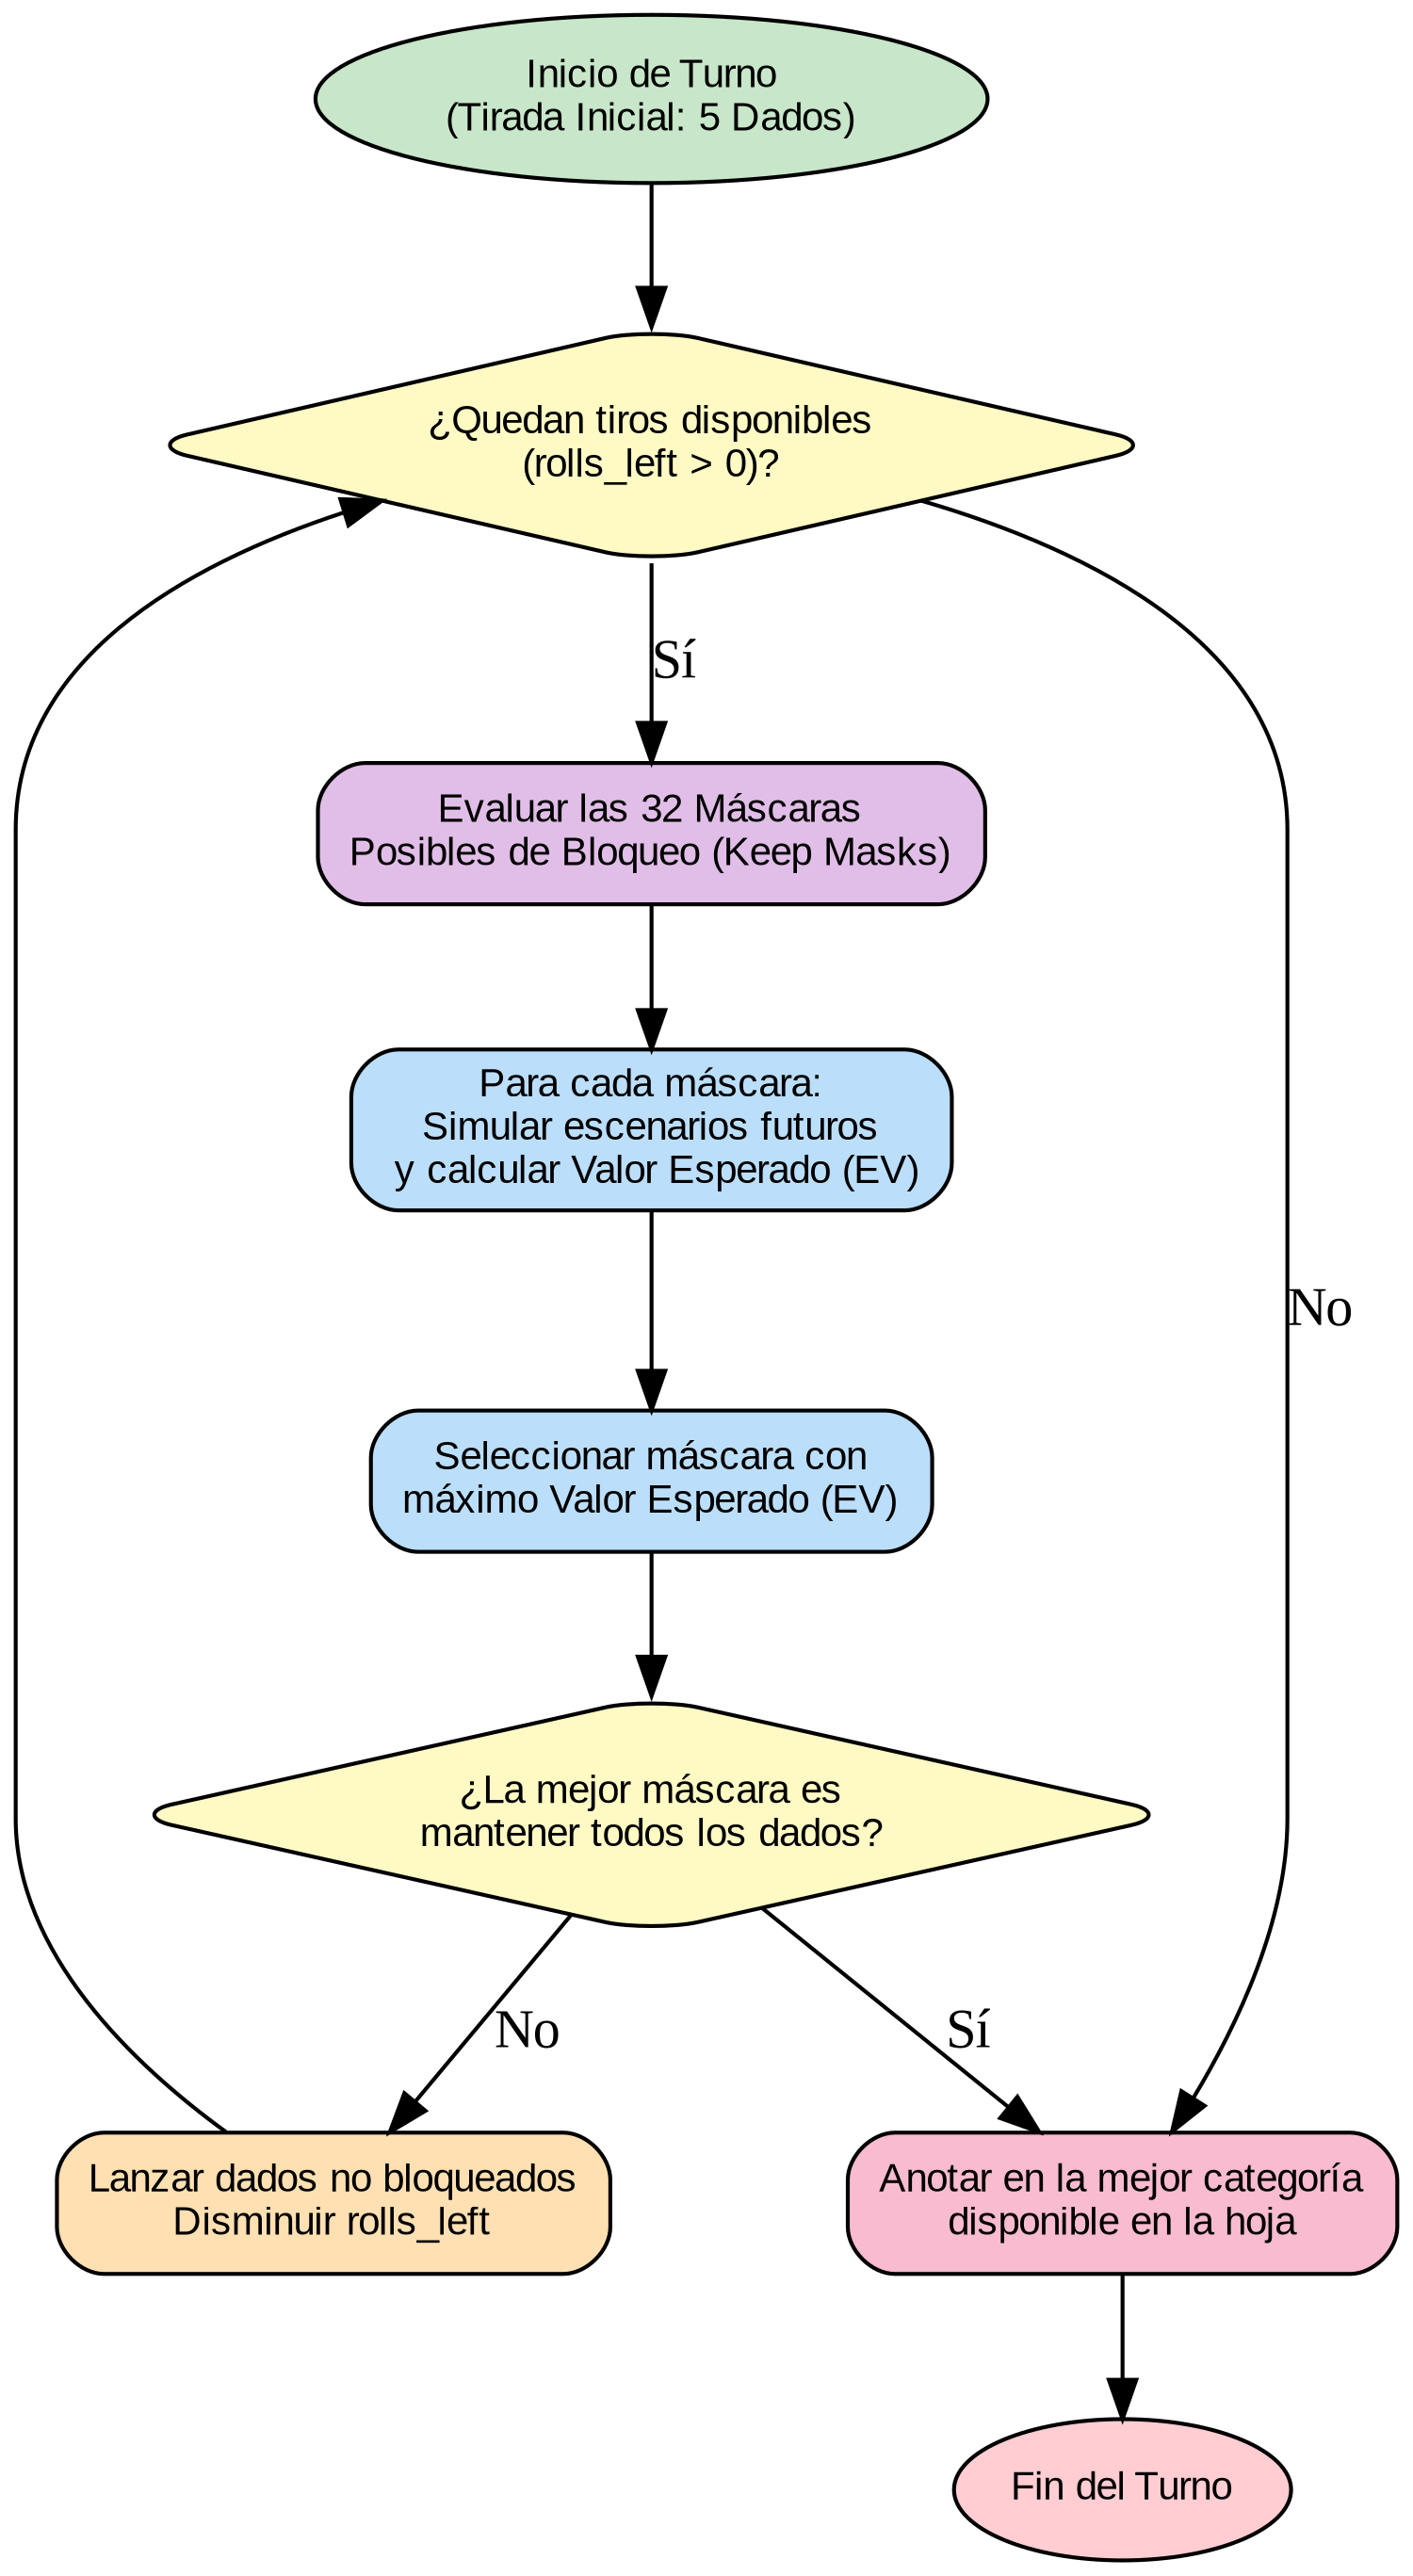

Diagrama generado correctamente: /content/diagrama_flujo_yahtzee.png


In [ ]:

from graphviz import Digraph
from IPython.display import Image, display

# Crear el diagrama de flujo de Yahtzee
dot = Digraph(comment='Algoritmo Yahtzee Montecarlo', format='png')
dot.attr(rankdir='TB', size='8,10', dpi='300')

dot.attr(
    'node',
    shape='box',
    style='filled,rounded',
    color='black',
    fillcolor='#E3F2FD',
    fontname='Arial',
    fontsize='10'
)

dot.node('inicio', 'Inicio de Turno\n(Tirada Inicial: 5 Dados)',
         fillcolor='#C8E6C9', shape='ellipse')

dot.node('eval_tiros', '¿Quedan tiros disponibles\n(rolls_left > 0)?',
         shape='diamond', fillcolor='#FFF9C4')

dot.node('eval_mascaras', 'Evaluar las 32 Máscaras\nPosibles de Bloqueo (Keep Masks)',
         fillcolor='#E1BEE7')

dot.node('montecarlo', 'Para cada máscara:\nSimular escenarios futuros\n y calcular Valor Esperado (EV)',
         fillcolor='#BBDEFB')

dot.node('mejor_mascara', 'Seleccionar máscara con\nmáximo Valor Esperado (EV)',
         fillcolor='#BBDEFB')

dot.node('plantarse', '¿La mejor máscara es\nmantener todos los dados?',
         shape='diamond', fillcolor='#FFF9C4')

dot.node('actualizar_dados', 'Lanzar dados no bloqueados\nDisminuir rolls_left',
         fillcolor='#FFE0B2')

dot.node('anotar', 'Anotar en la mejor categoría\ndisponible en la hoja',
         fillcolor='#F8BBD0')

dot.node('fin', 'Fin del Turno',
         fillcolor='#FFCDD2', shape='ellipse')

dot.edge('inicio', 'eval_tiros')
dot.edge('eval_tiros', 'eval_mascaras', label='Sí')
dot.edge('eval_tiros', 'anotar', label='No')
dot.edge('eval_mascaras', 'montecarlo')
dot.edge('montecarlo', 'mejor_mascara')
dot.edge('mejor_mascara', 'plantarse')
dot.edge('plantarse', 'anotar', label='Sí')
dot.edge('plantarse', 'actualizar_dados', label='No')
dot.edge('actualizar_dados', 'eval_tiros')
dot.edge('anotar', 'fin')

# Guardar y mostrar
ruta = dot.render(
    filename='/content/diagrama_flujo_yahtzee',
    cleanup=True
)

display(Image(filename=ruta))
print("Diagrama generado correctamente:", ruta)
